# **ST1519 Agile MLOps CA1 — PBI 2: Logistic Regression Fraud Model**

**Team member:** Thawdar Lin Wai (Yue Liang)

**Runs:** `LR_safe` (production-eligible) and `LR_full` (exploratory leakage check)

---

## **1. Model Objective**

- **Goal:** predict whether an SP-buy order is fraud (`is_fraud = 1`) using information available when the order is assessed
- **Business rule (PO):** prioritise **high precision** while keeping **reasonable recall**, because analysts can only review a limited number of flagged orders
- **Extra check:** compare the safe and full feature sets to see whether the 10 customer snapshot features may leak future information

## **2. Why Logistic Regression**

Logistic Regression gives each feature a **weight (coefficient)**, adds them up, and turns the total into a fraud probability between 0 and 1.

**Why this model:**
- **Explainable:** each coefficient shows whether a feature raises or lowers the fraud risk, and by how much
- **Fast:** trains in about 2 seconds on 666,000 orders, which fits the 3-minute retraining requirement (PBI 5)
- **Baseline:** a simple linear model to compare the more complex models against

**Main weakness:**
- It only learns **straight-line (linear) relationships**. It cannot combine features by itself (for example, country together with payment method), so tree-based models may score higher

**Preprocessing:**
- **StandardScaler** puts every feature on the same scale, so a feature with large values (e.g. `account_age_days`) does not dominate
- The scaler sits inside a **Pipeline**, so it is fitted on the training data only

---

## **3. Setup**

All training code lives in **`src/logistic_regression.py`**, using the team's shared helpers in **`src/model_utils.py`**.
This notebook only calls those functions, so automated retraining (PBI 5) runs the **same code** without opening the notebook:

```powershell
python src/logistic_regression.py            # trains LR_safe + LR_full and logs to MLflow
```

In [16]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Find the repository root so "src/" can be imported (works from notebooks/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_split.py").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import model_utils as mu                       # shared loading / evaluation / MLflow helpers
import logistic_regression as lr               # this notebook's model
from data_processing import SNAPSHOT_FEATURES  # 10 uncertain customer snapshot features
from data_split import create_split_labels      # team's shared chronological split

%matplotlib inline
# model_utils switches matplotlib to a file-only backend; this turns notebook charts back on

# ---- Configuration (no personal paths or secrets in code) ----
DATA_DIR = os.environ.get("FRAUD_DATA_DIR", REPO_ROOT / "data" / "processed")
OUTPUT_DIR = REPO_ROOT / "outputs"     # local plots/models (not committed)
RUN_SEARCH = True                      # False = skip the search and use the saved settings
LOG_TO_MLFLOW = True                   # uses $MLFLOW_TRACKING_URI, else a local mlruns/ store
DEVELOPER = lr.DEVELOPER               # "yueliang" unless $MODEL_DEVELOPER is set

pd.set_option("display.float_format", "{:.4f}".format)
print("Repository:", REPO_ROOT)
print("Random seed:", mu.RANDOM_SEED)

Repository: c:\Users\yyuel\OneDrive\Documents\Y2 S2\Agile MLOPs\MLOps_CA1_group5
Random seed: 42


---

## **4. Load and Validate Data**

Both processed files from PBI 1 are loaded and checked:

- **Required columns** exist and `is_fraud` only contains 0 and 1
- **No duplicate orders** (`country_code` + `order_id` is the order key)
- **No missing or infinite values** in any feature
- **Same orders and labels** in both files, in the same order

The **SHA-256 checksum** identifies the exact file version, so the team can confirm everyone used the same data.

In [17]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)

df_safe = mu.load_feature_data(safe_path)   # raises an error if any check fails
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)

checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
pd.DataFrame({
    "rows": [len(df_safe), len(df_full)],
    "columns": [df_safe.shape[1], df_full.shape[1]],
    "features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "fraud_rate_%": [df_safe["is_fraud"].mean() * 100, df_full["is_fraud"].mean() * 100],
    "sha256": [checksums["safe"][:12], checksums["full"][:12]],
}, index=["safe", "full"])

,rows,columns,features,fraud_rate_%,sha256
safe,949872,36,31,10.9933,656a05ca1189
full,949872,46,41,10.9933,d5abc1ac0ce1


**Observations:**
- **All checks passed:** both files have **949,872 orders** with the same fraud rate (**10.99%**)
- **Safe:** 36 columns = 4 metadata + **31 features** + `is_fraud`
- **Full:** 46 columns = 4 metadata + **41 features** + `is_fraud`

---

## **5. Features**

- **Not model inputs:** `country_code`, `order_id`, `customer_id`, `order_date` (kept for tracking and splitting) and the target `is_fraud`
- **Country is still used** through the one-hot columns (`country_code_BD`, `country_code_MY`, ...)
- **`refund_value` is never a feature:** every fraud order has a refund of 0, so it is recorded after the fraud decision (target leakage)
- **Full dataset:** has 10 extra customer snapshot features that may include activity after the order (Assumption 19)

In [18]:
safe_features = mu.get_feature_columns(df_safe)   # also checks no forbidden column is a feature
full_features = mu.get_feature_columns(df_full)
extra_features = [f for f in full_features if f not in safe_features]

print("Safe features:", len(safe_features))
print("Full features:", len(full_features))
print("Extra features in full = SNAPSHOT_FEATURES:", sorted(extra_features) == sorted(SNAPSHOT_FEATURES))
print("refund_value in either dataset:", "refund_value" in df_safe.columns or "refund_value" in df_full.columns)

Safe features: 31
Full features: 41
Extra features in full = SNAPSHOT_FEATURES: True
refund_value in either dataset: False


**Observations:**
- The 10 extra features in the full file are **exactly** the snapshot features from Assumption 19
- `refund_value` is in **neither** file, so there is no target leakage from refunds

---

## **6. Shared Chronological Split**

`create_split_labels()` from `src/data_split.py` is reused, so every teammate and both datasets use **the same orders**:

- **Train:** up to 15 Mar 2023, used to fit the model
- **Validation:** 16 Mar to 13 Apr 2023, used to choose hyperparameters and the threshold
- **Test:** from 14 Apr 2023, used **once** for the final scores

The split is by date because the model will be used on **future** orders.

In [19]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full)), "Safe and full splits differ!"

split_summary = (df_safe.assign(split=split)
                 .groupby("split")
                 .agg(first_date=("order_date", "min"), last_date=("order_date", "max"),
                      orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
                      fraud_rate=("is_fraud", "mean"))
                 .loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = split_summary["orders"] / len(df_safe) * 100
split_summary

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.1015,70.1017
Validation,2023-03-16,2023-04-13,139874,18993,0.1358,14.7256
Test,2023-04-14,2023-05-11,144122,17835,0.1237,15.1728


**Observations:**
- **Train:** 665,876 orders (70.1%), fraud rate **10.15%**
- **Validation:** 139,874 orders (14.7%), fraud rate **13.58%**
- **Test:** 144,122 orders (15.2%), fraud rate **12.37%**
- The fraud rate is **higher in later periods**, so the data changes over time

---

## **7. Evaluation Method and Threshold Rule**

### **7.1 Metrics**

| Metric | Simple meaning |
|---|---|
| **Precision** | When the model flags an order, how often is it really fraud? |
| **Recall** | Out of all fraud orders, how many did the model catch? |
| **F1** | One score that balances precision and recall |
| **PR-AUC** | How well the model ranks fraud above normal orders overall. Does not depend on the threshold |

- **Precision is the primary metric** (team standard): analysts can only review a limited number of orders, so flagged orders must usually be fraud
- **Recall is the secondary metric:** once precision is high enough, catch as much fraud as possible
- **PR-AUC is used to compare models across the team:** teammates may use different threshold rules, so precision alone is not a fair comparison. PR-AUC does not depend on the threshold. A random guess scores about **0.12** (the fraud rate)
- **Accuracy is not used:** saying "not fraud" for every order would already be about **88%** correct, while catching zero fraud

### **7.2 Threshold Rule**

The model gives each order a **fraud probability** from 0 to 1. The **threshold** is the cut-off: orders above it are flagged as fraud.

| Threshold | What happens |
|---|---|
| **Low** (e.g. 0.5) | Flags many orders, catches more fraud, but also flags many genuine customers |
| **High** (e.g. 0.86) | Flags fewer orders, most are real fraud, but more fraud is missed |

**Rule used:**
1. **Precision must be at least 70%**, so at least **7 in 10 flagged orders are real fraud** (primary metric)
2. Among the thresholds that meet this, pick the one that **catches the most fraud** (secondary metric: recall)

**Why this rule:**
- **Matches the PO and the team standard:** precision first, then recall
- **Not just the highest precision:** that would only flag a few orders the model is most sure about, so almost no fraud would be caught
- **Not the default 0.5:** it flags too many genuine customers (checked in Section 10)
- **Chosen on validation only:** the test set is not used, so the test scores stay fair

In [20]:
print("Threshold rule:", lr.THRESHOLD_RULE)
print("Precision target:", lr.PRECISION_TARGET)

Threshold rule: highest recall with validation precision >= 70%
Precision target: 0.7


---

## **8. Hyperparameter Search**

8 models are trained on **safe Train** and scored on **safe Validation**. The test set is not used.

| Hyperparameter | Values tried | Why |
|---|---|---|
| `C` | 0.01, 0.1, 1, 10 | Regularisation strength. Smaller `C` keeps the coefficients smaller (less overfitting) |
| `class_weight` | None, balanced | Whether giving fraud orders more weight helps with the class imbalance |
| `solver` | fixed: lbfgs | Standard solver for this size of data |
| `max_iter` | fixed: 2000 | Enough iterations for the model to converge |
| `random_state` | fixed: 42 | Same results every run |

**Ranking:** by validation **PR-AUC**. Recall at 70% precision is also shown, since that is how the model will be used.

In [21]:
if RUN_SEARCH:
    tuning_table, params = lr.tune(df_safe)
    if LOG_TO_MLFLOW:
        mu.log_tuning_table(tuning_table, "logistic_regression_tuning", developer=DEVELOPER)
    display(tuning_table)
else:
    params = lr.SELECTED_PARAMS

print("Selected hyperparameters:", params)
print("Same as SELECTED_PARAMS saved in src/logistic_regression.py:", params == lr.SELECTED_PARAMS)

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/yyuel/OneDrive/Documents/Y2 S2/Agile MLOPs/MLOps_CA1_group5/mlruns/mlflow.db


,C,class_weight,val_average_precision,val_roc_auc,val_recall_at_70%_precision,train_average_precision,train_seconds
0,0.0100,balanced,0.4610,0.7939,0.1190,0.3152,1.8700
1,0.1000,balanced,0.4610,0.7939,0.1188,0.3152,1.3600
2,1.0000,balanced,0.4610,0.7939,0.1188,0.3152,1.8000
3,10.0000,balanced,0.4610,0.7939,0.1189,0.3152,2.1100
4,0.0100,None,0.4587,0.7927,0.1252,0.3165,1.0800
5,0.1000,None,0.4586,0.7924,0.1261,0.3165,1.0800
6,1.0000,None,0.4586,0.7924,0.1262,0.3165,1.6700
7,10.0000,None,0.4586,0.7924,0.1262,0.3165,1.6700


Selected hyperparameters: {'C': 0.01, 'class_weight': 'balanced', 'max_iter': 2000, 'solver': 'lbfgs', 'random_state': 42}
Same as SELECTED_PARAMS saved in src/logistic_regression.py: True


**Observations:**
- **`C` makes almost no difference:** validation PR-AUC only changes in the 4th decimal place. With 666,000 training orders and only 31 features, the model has too much data to overfit, so regularisation has little effect
- **`class_weight="balanced"`** gives a slightly higher PR-AUC (**0.4610** vs **0.4587**), but slightly lower recall at 70% precision (**0.119** vs **0.126**). Both differences are very small
- **Selected:** `C=0.01`, `class_weight="balanced"` (highest validation PR-AUC), saved as `SELECTED_PARAMS` in `src/logistic_regression.py`
- **Validation PR-AUC (0.46) is higher than train PR-AUC (0.32)** because PR-AUC depends on the fraud rate, which is higher in validation (13.6% vs 10.2%). It is not a sign of a problem

---

## **9. Model Training**

### **9.1 Safe Dataset (LR_safe)**

`mu.run_training()` does the same steps for every run:

1. Split with the shared chronological function
2. Train on **Train** only
3. Choose the threshold on **Validation** with the 70% precision rule
4. Score **Test** once with that threshold
5. Save plots and the model locally, and log everything to MLflow

`LR_safe` is the **production-eligible** run.

In [22]:
mlflow_location = mu.setup_mlflow() if LOG_TO_MLFLOW else None
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location, developer=DEVELOPER,
              snapshot_features=SNAPSHOT_FEATURES, trusted_types=lr.TRUSTED_TYPES)

result_safe, model_safe = mu.run_training(
    lr.ALGORITHM, lr.SHORT_NAME, "safe", df_safe, lr.train_model, params,
    lr.feature_importance, dataset_sha256=checksums["safe"],
    threshold_fn=lr.choose_threshold_min_precision, threshold_rule=lr.THRESHOLD_RULE, **common)

print(f"Threshold chosen on validation: {result_safe['threshold']:.4f}")
print(f"Training time: {result_safe['train_seconds']:.1f} s")
print("Extra training info:", result_safe["extra_metrics"])

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/yyuel/OneDrive/Documents/Y2 S2/Agile MLOPs/MLOps_CA1_group5/mlruns/mlflow.db
Threshold chosen on validation: 0.8596
Training time: 1.2 s
Extra training info: {'iterations': 16.0}


### **9.2 Full Dataset (LR_full)**

- **Same** hyperparameters, seed, split and **threshold** as `LR_safe`
- The **only** difference is the 10 snapshot features, so any change in results comes from them
- Tagged `exploratory=true` and `production_eligible=false` in MLflow, so it must **never** be registered or promoted

In [23]:
result_full, model_full = mu.run_training(
    lr.ALGORITHM, lr.SHORT_NAME, "full", df_full, lr.train_model, params,
    lr.feature_importance, threshold=result_safe["threshold"],   # reuse the safe threshold
    dataset_sha256=checksums["full"], **common)

print(f"Threshold reused: {result_full['threshold']:.4f}")
print(f"Training time: {result_full['train_seconds']:.1f} s")

Threshold reused: 0.8596
Training time: 1.6 s


---

## **10. Validation Results and Threshold Check**

Validation results of `LR_safe` at the chosen threshold, compared with the default threshold of 0.5.

In [24]:
parts, _ = mu.split_data(df_safe)
X_val, y_val = parts["Validation"]
val_prob = model_safe.predict_proba(X_val)[:, 1]

threshold_check = pd.DataFrame({
    f"chosen ({result_safe['threshold']:.4f})": mu.evaluate(y_val, val_prob, result_safe["threshold"]),
    "sklearn default (0.5)": mu.evaluate(y_val, val_prob, 0.5),
}).loc[["precision", "recall", "f1", "average_precision", "tp", "fp"]]
threshold_check.loc["orders_flagged"] = threshold_check.loc["tp"] + threshold_check.loc["fp"]

# show counts as whole numbers and scores with 4 decimals
shown = threshold_check.round(4).astype(object)
for row in ["tp", "fp", "orders_flagged"]:
    shown.loc[row] = threshold_check.loc[row].astype(int)
shown

,chosen (0.8596),sklearn default (0.5)
precision,0.7001,0.3190
recall,0.1190,0.7413
f1,0.2034,0.4460
average_precision,0.4610,0.4610
tp,2260,14079
fp,968,30060
orders_flagged,3228,44139


**Observations:**

| | Chosen (0.8596) | Default (0.5) |
|---|---|---|
| **Orders flagged** | 3,228 | 44,139 |
| **Real fraud caught** | 2,260 | 14,079 |
| **Genuine customers wrongly flagged** | 968 | 30,060 |
| **Precision** | 70.0% | 31.9% |
| **Recall** | 11.9% | 74.1% |

- **Chosen threshold:** 7 in 10 flagged orders are real fraud, but it only catches about 1 in 8 fraud orders
- **Default 0.5:** catches about 3 in 4 fraud orders, but **2 in 3 flagged orders are genuine customers**, which is far too many for analysts to review
- **PR-AUC is the same (0.4610):** it measures how well the model ranks orders overall, so changing the threshold does not affect it

---

## **11. Test Results**

Results on the **test** period (14 Apr to 11 May 2023), which was not used for any decision.

In [25]:
results = [result_safe, result_full]
comparison = mu.comparison_table(results)
comparison

,LR_safe,LR_full
Accuracy,0.8842,0.8828
Precision (fraud),0.6062,0.5384
Recall (fraud),0.1831,0.3710
F1 (fraud),0.2812,0.4393
Average precision,0.3975,0.4493
ROC-AUC,0.7721,0.8252
TP,3265,6616
FP,2121,5673
FN,14570,11219
TN,124166,120614


**How to read this table:**

| Row | Meaning |
|---|---|
| **TP** (true positive) | Fraud, and the model flagged it (caught) |
| **FP** (false positive) | Not fraud, but the model flagged it (false alarm) |
| **FN** (false negative) | Fraud, but the model missed it |
| **TN** (true negative) | Not fraud, and the model left it alone |
| **Production eligible** | Only LR_safe can be used for real, since LR_full uses the uncertain snapshot features |

**Observations (LR_safe on test):**
- **Orders flagged:** 5,386 (3,265 real fraud + 2,121 false alarms)
- **Precision 60.6%:** about **6 in 10** flagged orders are real fraud, about **5 times** better than the fraud rate of 12.4%
- **Recall 18.3%:** it catches about **1 in 5** fraud orders and misses 14,570
- **Accuracy 88.4% is misleading:** saying "not fraud" for every order would already score about 87.6%
- **Fast:** trains in under 2 seconds and predicts all 144,122 test orders in under 0.1 seconds
- **LR_full** is only for the leakage check (Section 12), so it is not compared here

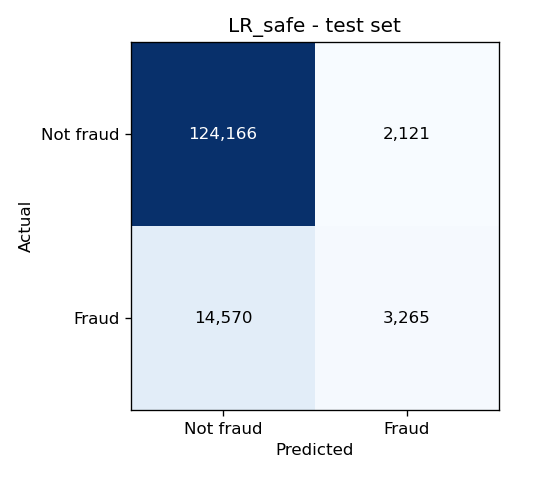

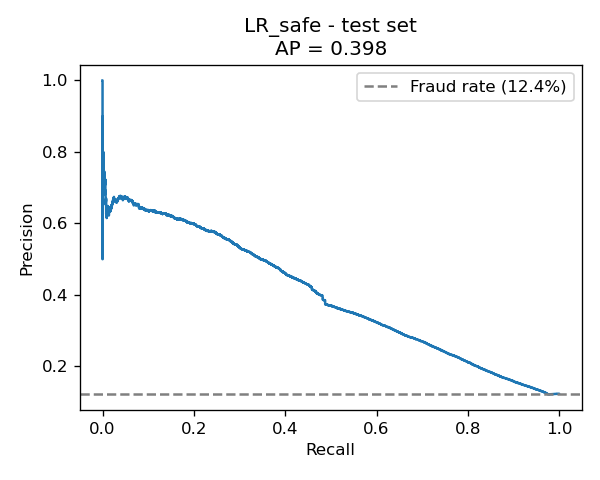

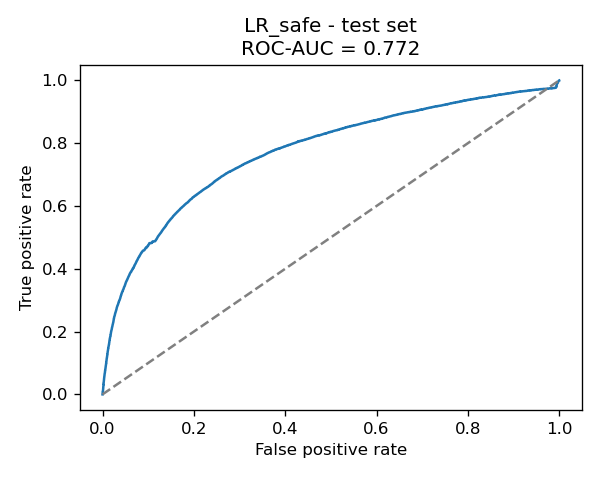

In [26]:
plots = OUTPUT_DIR / "LR_safe" / "plots"
display(Image(plots / "confusion_matrix_test.png"), Image(plots / "precision_recall_test.png"),
        Image(plots / "roc_test.png"))

In [27]:
# Same model, same threshold: compare validation and test side by side
X_test, y_test = parts["Test"]
test_prob = model_safe.predict_proba(X_test)[:, 1]

val_vs_test = pd.DataFrame({
    "Validation": mu.evaluate(y_val, val_prob, result_safe["threshold"]),
    "Test": mu.evaluate(y_test, test_prob, result_safe["threshold"]),
}).loc[["precision", "recall", "average_precision", "tp", "fp"]]
val_vs_test.loc["orders_flagged"] = val_vs_test.loc["tp"] + val_vs_test.loc["fp"]
val_vs_test["change"] = val_vs_test["Test"] - val_vs_test["Validation"]

# show counts as whole numbers and scores with 4 decimals
shown = val_vs_test.round(4).astype(object)
for row in ["tp", "fp", "orders_flagged"]:
    shown.loc[row] = val_vs_test.loc[row].astype(int)
shown

,Validation,Test,change
precision,0.7001,0.6062,-0.0939
recall,0.1190,0.1831,0.0641
average_precision,0.4610,0.3975,-0.0635
tp,2260,3265,1005
fp,968,2121,1153
orders_flagged,3228,5386,2158


**Validation vs Test (LR_safe):**

| | Validation | Test | Change |
|---|---|---|---|
| **Precision** | 0.700 | 0.606 | lower |
| **Recall** | 0.119 | 0.183 | higher |
| **PR-AUC** | 0.461 | 0.398 | lower |
| **Orders flagged** | 3,228 | 5,386 | more |


- **Precision dropped from 70% to 61%:** the threshold was chosen on mid-March to mid-April orders, but the fraud pattern changed in the test period (**data drift**)
- **Recall went up only because more orders were flagged**, not because the model got better
- **PR-AUC fell from 0.461 to 0.398**, which confirms the model is less good at spotting fraud in newer orders
- **This is why regular retraining (PBI 5) matters:** the model needs to learn from recent orders to keep up

---

## **12. Safe versus Full Comparison**

,LR_safe,LR_full,full - safe
Precision (fraud),0.6062,0.5384,-0.0678
Recall (fraud),0.1831,0.3710,0.1879
F1 (fraud),0.2812,0.4393,0.1580
Average precision,0.3975,0.4493,0.0517
ROC-AUC,0.7721,0.8252,0.0531


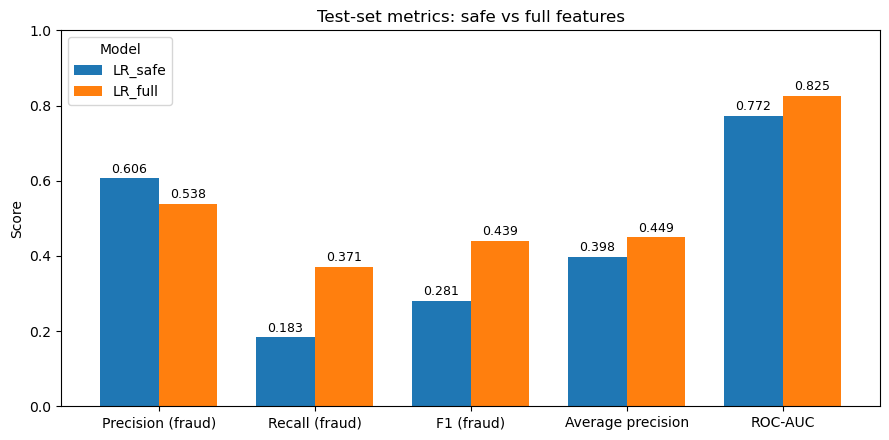

In [28]:
metrics = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC"]
diff = comparison.loc[metrics].astype(float)
diff["full - safe"] = diff["LR_full"] - diff["LR_safe"]
display(diff.round(4))

ax = diff[["LR_safe", "LR_full"]].plot.bar(figsize=(9, 4.5), rot=0, width=0.75)
for bars in ax.containers:                      # one container per model (safe, full)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
ax.set_title("Test-set metrics: safe vs full features")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model", loc="upper left")
plt.tight_layout()
plt.show()

**Observations:**

| | LR_safe (31 features) | LR_full (41 features) | Difference |
|---|---|---|---|
| **PR-AUC** | 0.398 | 0.449 | **+0.052** |
| **ROC-AUC** | 0.772 | 0.825 | **+0.053** |
| **Recall** | 0.183 | 0.371 | about double |
| **Precision** | 0.606 | 0.538 | lower |

- **Adding the 10 snapshot features makes the model score higher**
- **Precision is lower** because LR_full uses the same threshold as LR_safe, and with the extra features it gives higher probabilities to more orders, so it flags more of them
- **Question:** are the snapshot features genuinely useful, or do they contain **future information** the model should not have? A higher score alone cannot answer this, so Section 12.1 checks it

### **12.1 Data Leakage Check by Month**

- A higher score with the full features does **not** prove leakage, since the features might simply be useful
- If the snapshot was taken around **11 May 2023**, its "last 50 days" window covers about **22 Mar to 11 May**
- If the snapshot features leak, their advantage should **grow for orders closer to the snapshot date**
- Only months the model never trained on (after 15 Mar) are used

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.9400,0.4767,0.4697,-0.0070
1,2023-04,148855,12.6100,0.3979,0.4330,0.0350
2,2023-05,57450,12.5700,0.4324,0.4798,0.0475


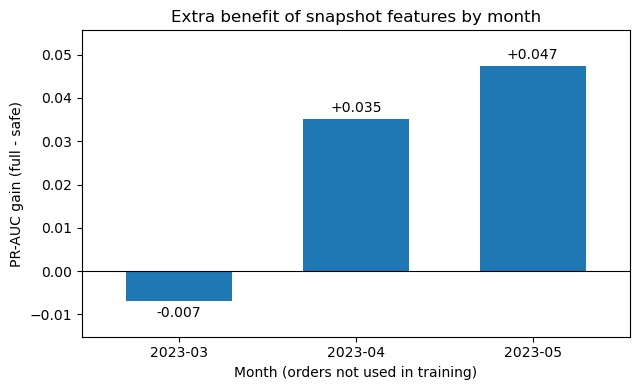

In [29]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)

ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False,
                   rot=0, figsize=(6.5, 4), width=0.6)
ax.bar_label(ax.containers[0], fmt="%+.3f", padding=3, fontsize=10)   # value on each bar
ax.axhline(0, color="black", linewidth=0.8)
ax.margins(y=0.15)                                                     # room for the labels
ax.set_xlabel("Month (orders not used in training)")
ax.set_ylabel("PR-AUC gain (full - safe)")
ax.set_title("Extra benefit of snapshot features by month")
plt.tight_layout()
plt.show()

**Observations:**

| Month (not used in training) | Extra PR-AUC from snapshot features |
|---|---|
| **March** (16th to 31st) | **−0.007** (no help) |
| **April** | **+0.035** |
| **May** (1st to 11th) | **+0.048** (most help) |

- **The closer the orders are to May, the more the snapshot features help**
- **Why this matters:** the snapshot was likely taken around 11 May. If it contains activity that happened after an order, it would help most for orders close to that date, which is exactly what we see
- **This points to leakage**, but is **not proof**, since fraud patterns also change over time and the snapshot date cannot be confirmed
- **Decision:** to be safe, the snapshot features stay **out of the production model** (Assumption 19)

**Analysis:**

| Month | Safe model PR-AUC | Full model PR-AUC | Gain | Gain as % of safe |
|---|---|---|---|---|
| **March** | 0.477 | 0.470 | −0.007 | about −1% |
| **April** | 0.398 | 0.433 | +0.035 | about 9% |
| **May** | 0.432 | 0.480 | +0.048 | about 11% |

- **No steady benefit:** in late March the snapshot features slightly **hurt**, so they add nothing for orders far from the snapshot date. All of their benefit appears only as orders get closer to May, which is exactly what leakage would look like
- **The full model's results are likely too optimistic:** LR_full's test PR-AUC of 0.449 would probably not hold in real use, so **LR_safe's 0.398 is the more honest estimate** of real performance
- **Real-world risk:** in production, the snapshot features would be calculated when the order comes in, without any future activity. A model trained with future information would then perform worse than its test results suggest
- **The safe model also gets worse over time** (0.477 in late March to 0.398 in April) without any snapshot features. This is the **data drift** seen in Section 11, and it is separate from the leakage

**Recommendation:**
- Ask the data owner for the **exact snapshot date**, or for customer history with dates, so these features can be calculated **as of each order's date**. Then they could be used safely
- Until then, keep the snapshot features **out** of all production models

---

## **13. Coefficients (Feature Importance)**

- Coefficients are on the **scaled** features, so their sizes can be compared
- **Positive** = raises the fraud probability, **negative** = lowers it
- Ranked by size, since both directions matter

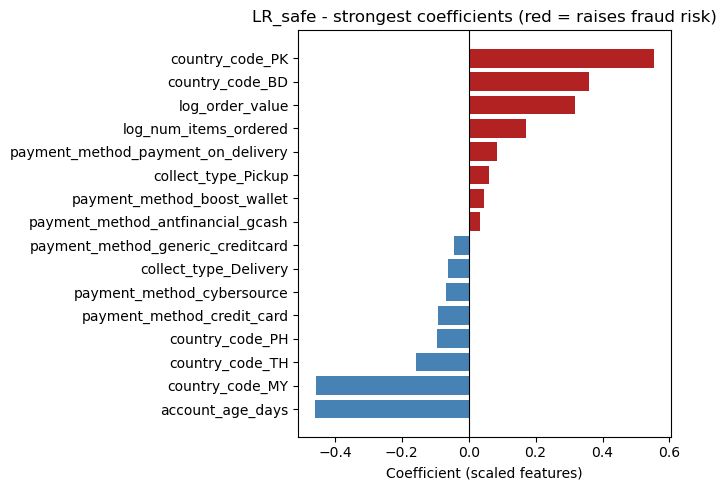

,feature,coefficient,importance
0,country_code_PK,0.5529,0.5529
1,account_age_days,-0.4585,0.4585
2,country_code_MY,-0.4566,0.4566
3,country_code_BD,0.3602,0.3602
4,log_order_value,0.3181,0.3181
5,log_num_items_ordered,0.1710,0.1710
6,country_code_TH,-0.1565,0.1565
7,country_code_PH,-0.0937,0.0937
8,payment_method_credit_card,-0.0918,0.0918
9,payment_method_payment_on_delivery,0.0839,0.0839


In [30]:
coef = result_safe["importance"]
top = pd.concat([coef.nlargest(8, "coefficient"), coef.nsmallest(8, "coefficient")])
top = top.sort_values("coefficient")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["feature"], top["coefficient"], color=["firebrick" if c > 0 else "steelblue" for c in top["coefficient"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (scaled features)")
ax.set_title("LR_safe - strongest coefficients (red = raises fraud risk)")
plt.tight_layout()
plt.show()

coef.head(10)

**Observations:**

The chart shows what the model learned. Each bar is a feature's **weight**:
- **Red (positive):** makes an order **more** likely to be flagged as fraud
- **Blue (negative):** makes an order **less** likely to be flagged as fraud
- **Longer bar:** stronger effect

| Effect | Feature | Weight | Simple meaning |
|---|---|---|---|
| **Raises risk** | `country_code_PK` | +0.55 | Orders from Pakistan |
| | `country_code_BD` | +0.36 | Orders from Bangladesh |
| | `log_order_value` | +0.32 | Bigger orders |
| **Lowers risk** | `account_age_days` | −0.46 | Older accounts |
| | `country_code_MY` | −0.46 | Orders from Malaysia |

- **Country matters most:** 3 of the 5 strongest features are countries
- **Payment method and collection type** barely matter (all weights below 0.1)
- **Why this is useful:** with Logistic Regression we can explain **why** an order was flagged, which helps analysts trust the model

**Analysis:**

- **Older accounts are safer:** fraudsters often create **new accounts** to commit fraud, then abandon them once caught. A customer who has used SP-buy for a long time has built a history, which makes them less likely to be a fraudster
- **Bigger orders are riskier:** a fraudster wants to get as much as possible from each attempt, so fraud orders tend to be **larger**. Small everyday orders are less worth the risk
- **Country has the biggest effect:** fraud rates differ a lot between countries (for example Pakistan and Bangladesh much higher, Malaysia lower). This could be due to differences in payment checks, delivery methods or organised fraud in certain regions, but the data does not tell us the exact reason
- **Payment method and collection type barely matter:** once country, account age and order value are known, how the customer pays or collects adds very little extra information

**Things to be careful about:**

- **Linked, not caused:** these weights show patterns, not causes. Being from Pakistan does not make a customer a fraudster, it only means fraud was more common in those orders
- **Fairness risk:** relying heavily on country could unfairly flag genuine customers from high-risk countries. The analysts should review flagged orders, not block them automatically
- **Weights depend on each other:** each weight is measured while the other features are held the same, so a feature's effect can change if other features are added or removed

---

## **14. MLflow Experiment Tracking**

Logging uses the team's shared **`src/mlflow_utils.py`** through `model_utils`:

- **Experiment:** `SP-buy-Fraud-Detection`
- **Run names:** `{member}_{algorithm}_{dataset_version}_{model_version}`, e.g. `yueliang_logistic_regression_safe_v1`
- **Tags:** `team_member`, `algorithm`, `dataset_version`, `model_version`, `production_eligible`, `exploratory`
- **Parameters:** hyperparameters, threshold, threshold rule, feature count, dataset SHA-256, row counts
- **Metrics:** validation and test metrics, TP/TN/FP/FN, training and inference time
- **Artifacts:** confusion matrix, PR and ROC curves, coefficients (plot and CSV), and the model with its signature

The server address is read from **`MLFLOW_TRACKING_URI`**, so nothing is hard-coded. If it is not set, runs go to a local test store (`mlruns/`, git-ignored).

In [31]:
for r in results:
    print(f"{mu.mlflow_run_name(r):<40} run_id={r.get('mlflow_run_id', 'not logged')}  "
          f"production_eligible={r['production_eligible']}  location={mlflow_location}")

yueliang_logistic_regression_safe_v1     run_id=696220e3dd1e404fa2f8aa5ddd5145b0  production_eligible=True  location=local
yueliang_logistic_regression_full_v1     run_id=342dbc73716340a19341e266090ca79f  production_eligible=False  location=local


---

## **15. Summary**

**Final model: LR_safe** (`C=0.01`, `class_weight="balanced"`, threshold **0.8596**)

**Results (test period 14 Apr to 11 May 2023)**

| | LR_safe | LR_full |
|---|---|---|
| **PR-AUC (average precision)** | 0.398 | 0.449 |
| **ROC-AUC** | 0.772 | 0.825 |
| **Fraud precision** | **0.606** | 0.538 |
| **Fraud recall** | 0.183 | 0.371 |
| **Fraud F1** | 0.281 | 0.439 |
| **Threshold** | 0.8596 | 0.8596 (reused) |
| **Training time** | about 1.5 s | about 2.5 s |
| **Production eligible** | **Yes** | No (exploratory) |

- **LR_full is not a real option:** its higher scores likely come from leaked snapshot features (Section 12.1)

**Validation vs Test (LR_safe)**

| | Validation | Test |
|---|---|---|
| **Precision** | 0.700 | 0.606 |
| **Recall** | 0.119 | 0.183 |
| **F1** | 0.203 | 0.281 |
| **PR-AUC** | 0.461 | 0.398 |
| **ROC-AUC** | 0.794 | 0.772 |

- **Validation precision is 0.700 by design:** the threshold rule lowers the threshold as far as possible while keeping precision at 70%, so it always lands at the edge. **Test precision is the real check**
- **Every score is lower on test except recall**, which rose only because more orders were flagged (data drift, Section 11)

**What the model learned:**
- **Main fraud patterns:** new accounts, bigger orders, and orders from Pakistan or Bangladesh
- **Main safe patterns:** older accounts and orders from Malaysia
- **Country** is the strongest group of features, while payment method and collection type add very little
- **Full explanation and cautions:** see Section 13 (Analysis)

**What this means for the business:**
- **Analyst workload:** over the 4-week test period, the model flagged **5,386** orders (about **190 per day**)
- **Useful flags:** about **6 in 10** flagged orders are real fraud, compared with about 1 in 8 if orders were picked at random
- **Genuine customers:** only **1.7%** of genuine orders were wrongly flagged, so most honest customers are not disturbed
- **Missed fraud:** about **4 in 5** fraud orders are still not flagged, so this model alone cannot stop most fraud
- **Trade-off:** on validation, the default threshold of 0.5 would flag 44,139 orders with only 32% precision, so 2 in 3 flagged orders would be genuine customers. The strict threshold keeps analysts focused on likely fraud

**Key findings:**
- **Precision held up reasonably on test:** 60.6%, still about **5 times** better than the fraud rate of 12.4%
- **Data drift:** precision dropped from 70% (validation) to 61% (test) as fraud patterns changed, so **regular retraining (PBI 5)** is important
- **Drift is not just a threshold problem:** the safe model's PR-AUC falls from 0.477 (late March) to 0.398 (April) in Section 12.1, so the model ranks fraud less well on newer orders, whatever threshold is used
- **Leakage check:** in late March the snapshot features did not help at all (−0.007), and their benefit only appears as orders get closer to May (+0.035 April, +0.048 May). This is exactly what leakage would look like, so LR_full's higher PR-AUC (0.449) is likely too optimistic and the snapshot features stay out (Assumption 19)
- **Fast:** trains in about 1.5 seconds, well within the 3-minute retraining requirement
- **Hyperparameters:** `C` has almost no effect with this much data, so tuning gives little improvement for this model

**Limitations:**
- **Simple patterns only:** Logistic Regression adds up each feature separately, so it cannot learn combinations such as "new account **and** large order **and** high-risk country". Tree-based models can, so they may rank fraud better
- **Scores are not real probabilities:** `class_weight="balanced"` pushes all scores upwards, so a score of 0.86 does not mean an 86% chance of fraud (orders above 0.86 were about 70% fraud on validation). The score should be read as a ranking, which is why the threshold is chosen from data instead of using 0.5
- **Threshold rule:** the 70% precision target is a team choice, and it could not be reached in a useful way on test
- **One time split:** results on other time periods may differ
- **Fairness:** country has a strong effect, so flagged orders should be reviewed by analysts, not blocked automatically
- **`account_age_days`** comes from the customer table, so its timing has not been formally confirmed

**Overall conclusion:**
- **LR_safe is a simple, explainable baseline:** the coefficients show exactly why an order is flagged, it trains in seconds, and about 6 in 10 flagged orders on test were real fraud
- **Its main weakness is low recall:** most fraud is still missed, so more complex models should be compared against it on PR-AUC
- **The biggest risk is drift:** regular retraining on recent orders is needed to keep precision close to the target

**Next steps:**
- Compare all team models on **test PR-AUC** in MLflow and register the top 2
- Retrain regularly on recent orders (PBI 5) and monitor precision after deployment